# 🔗 Uji Integrasi #1 — MIDI String Generator

**Penguji:** Ainun Widyah Astanti (Ketua) · **Acuan:** `docs/KONTRAK_MODUL.md`, `docs/REVIEW_INTEGRASI_01.md`

Notebook ini menguji **seluruh alur** dari file MIDI sampai file MIDI baru:

```
data/raw/*.mid → tokenizer.py → dataset.py → model.py → train.py → generate.py → outputs/generated/*.mid
```

**Cara pakai**
1. `Runtime → Change runtime type → T4 GPU`.
2. Jalankan sel **satu per satu dari atas** (Shift + Enter). Jangan lompat sel.
3. Setiap tahap diakhiri tulisan `✅ LULUS`. Jika muncul error, **berhenti**, salin traceback lengkapnya ke log, lalu laporkan ke pemilik modul.
4. Isi tabel hasil di sel paling bawah, lalu `File → Download → .ipynb` dan simpan ke `notebooks/` di repo.

## Tahap 0 — Persiapan lingkungan

In [1]:
# 0a. Cek GPU
import torch
print("PyTorch :", torch.__version__)
print("GPU     :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "TIDAK ADA (pakai CPU, training lebih lambat)")

PyTorch : 2.11.0+cu130
GPU     : Tesla T4


In [2]:
# 0b. Ambil kode TERBARU dari GitHub (hapus salinan lama jika ada)
%cd /content
!rm -rf midi-generator
!git clone -q https://github.com/AinunWidyah/midi-generator.git
%cd /content/midi-generator
print("Commit yang diuji:")
!git log --format="  %h  %an  %ad  %s" --date=format:"%d/%m %H:%M" -5

/content
/content/midi-generator
Commit yang diuji:
  5f48847  Laratha  02/11 14:04  Fix tokenizer: pakai TOKEN_TO_ID dari config
  246781f  AinunWidyah  02/11 14:09  [Ainun-ketua] review integrasi #1, kontrak v1.2, log keputusan
  eb7dc9b  NUR AISYA JAMIL  02/11 13:36  Refactor model import and update save_midi function
  c0bc3ad  NUR AISYA JAMIL  02/11 13:36  Replace MiniGPT with MiniMusicTransformer in train.py
  e19ce65  NUR AISYA JAMIL  29/10 12:48  Refactor train.py for improved argument parsing and structure


In [3]:
# 0c. Pasang library yang belum ada di Colab
!pip install -q pretty_midi
import sys
sys.path.insert(0, "/content/midi-generator/src")   # agar bisa `import tokenizer`, `import dataset`, dst.
import pretty_midi
print("pretty_midi:", pretty_midi.__version__)
!ls data/raw/nottingham | wc -l
print("☝️ jumlah file MIDI di data/raw/nottingham (harus 1034)")

pretty_midi: 0.2.11.post0
1034
☝️ jumlah file MIDI di data/raw/nottingham (harus 1034)


## Tahap 1 — `tokenizer.py` (Anggota 2)
Menguji perbaikan **B1** dan kontrak tokenizer: import, ukuran vocab 148, token ↔ ID, transposisi, dan round-trip.

In [4]:
# 1a. Self-test bawaan tokenizer (menguji B1: harus bisa di-import tanpa TypeError)
!python src/tokenizer.py data/raw/nottingham/ashover1.mid --out outputs/integrasi/roundtrip_ashover1.mid

Self-test berhasil: data/raw/nottingham/ashover1.mid
Jumlah token: 140
MIDI hasil decode: outputs/integrasi/roundtrip_ashover1.mid


In [5]:
# 1b. Uji round-trip musik: encode -> decode -> encode harus menghasilkan token yang SAMA
import tokenizer
from pathlib import Path

contoh = sorted(Path("data/raw/nottingham").glob("*.mid"))[:20]
lulus, gagal = 0, []
for f in contoh:
    try:
        t1 = tokenizer.encode(str(f))
        out = Path("outputs/integrasi/rt") / f.name
        tokenizer.decode(t1, str(out))
        t2 = tokenizer.encode(str(out))
        if t1 == t2:
            lulus += 1
        else:
            beda = next(i for i, (a, b) in enumerate(zip(t1, t2)) if a != b) if len(t1) == len(t2) else "panjang berbeda"
            gagal.append((f.name, len(t1), len(t2), beda))
    except Exception as e:
        gagal.append((f.name, "ERROR", str(e)[:80], ""))

print(f"Round-trip identik: {lulus}/{len(contoh)}")
for g in gagal:
    print("  ✗", g)
print("\nContoh 20 token pertama ashover1.mid:")
print(tokenizer.encode("data/raw/nottingham/ashover1.mid")[:20])
assert len(tokenizer.TOKEN_TO_ID) == 148, "Ukuran vocab bukan 148!"
print("\n✅ LULUS" if lulus == len(contoh) else "\n⚠️ Ada lagu yang round-trip-nya tidak identik — catat di log (lihat kolom di atas)")

Round-trip identik: 18/20
  ✗ ('ashover15.mid', 'ERROR', 'Tidak ditemukan track bernada monofonik pada file: ashover15.mid', '')
  ✗ ('ashover19.mid', 'ERROR', 'Tidak ditemukan track bernada monofonik pada file: ashover19.mid', '')

Contoh 20 token pertama ashover1.mid:
['<BOS>', 'REST', 'DUR_8', 'NOTE_76', 'DUR_4', 'NOTE_74', 'DUR_8', 'NOTE_71', 'DUR_4', 'NOTE_69', 'DUR_6', 'NOTE_71', 'DUR_2', 'NOTE_72', 'DUR_4', 'NOTE_71', 'DUR_8', 'NOTE_67', 'DUR_4', 'NOTE_69']

⚠️ Ada lagu yang round-trip-nya tidak identik — catat di log (lihat kolom di atas)


## Tahap 2 — Cek Asumsi 2 & 3 kontrak (durasi dan panjang lagu)
Asumsi 1 (monofonik) sudah terverifikasi 2,1%. Sel ini menghitung asumsi 2 dan 3 langsung dari hasil tokenizer.

In [6]:
import statistics, collections

files = sorted(Path("data/raw/nottingham").glob("*.mid"))
panjang, dur_counter, gagal_encode = [], collections.Counter(), []
for f in files:
    try:
        toks = tokenizer.encode(str(f))
    except Exception as e:
        gagal_encode.append(f.name)
        continue
    panjang.append(len(toks))
    dur_counter.update(t for t in toks if t.startswith("DUR_"))

total_dur = sum(dur_counter.values())
dur16 = dur_counter.get("DUR_16", 0)
print(f"Lagu berhasil di-encode : {len(panjang)} / {len(files)}  (gagal/non-monofonik: {len(gagal_encode)})")
print(f"Token per lagu          : min {min(panjang)}, median {statistics.median(panjang):.0f}, "
      f"rata-rata {statistics.mean(panjang):.0f}, maks {max(panjang)}")
print(f"Lagu > 256 token        : {sum(p > 256 for p in panjang)} ({sum(p > 256 for p in panjang)/len(panjang)*100:.1f}%)  -> dipotong per jendela, aman")
print(f"Token DUR_16 (batas atas, termasuk yang terpotong): {dur16} dari {total_dur} ({dur16/total_dur*100:.2f}%)")
print("\nDistribusi durasi:")
for d in range(1, 17):
    n = dur_counter.get(f"DUR_{d}", 0)
    print(f"  DUR_{d:<2} {n:6d}  {'█' * int(n / total_dur * 100)}")
print("\nAsumsi 2 aman jika DUR_16 < 5%. Jika jauh lebih besar, laporkan ke Ketua (pertimbangkan MAX_DURATION = 32).")

Lagu berhasil di-encode : 1012 / 1034  (gagal/non-monofonik: 22)
Token per lagu          : min 36, median 328, rata-rata 385, maks 5452
Lagu > 256 token        : 755 (74.6%)  -> dipotong per jendela, aman
Token DUR_16 (batas atas, termasuk yang terpotong): 290 dari 193940 (0.15%)

Distribusi durasi:
  DUR_1    9001  ████
  DUR_2  125416  ████████████████████████████████████████████████████████████████
  DUR_3    1081  
  DUR_4   45786  ███████████████████████
  DUR_5       1  
  DUR_6    6211  ███
  DUR_7       0  
  DUR_8    4571  ██
  DUR_9       0  
  DUR_10    260  
  DUR_11      0  
  DUR_12   1313  
  DUR_13      0  
  DUR_14      9  
  DUR_15      1  
  DUR_16    290  

Asumsi 2 aman jika DUR_16 < 5%. Jika jauh lebih besar, laporkan ke Ketua (pertimbangkan MAX_DURATION = 32).


## Tahap 3 — `model.py` (Ketua)

In [7]:
!python src/model.py --tahap 6

=== Tahap 6: Uji model lengkap ===
[6a] jumlah parameter: 3,297,792 (~3.30 juta)
[6b] input penuh (4, 256) -> logits (4, 256, 148)
[6c] model lengkap tetap causal: True
[6d] loss awal: 5.039 | teori tebakan acak ln(148) = 4.997
Tahap 6 LULUS ✅



## Tahap 4 — `dataset.py` (Anggota 2) + sambungan ke model
Menguji `create_dataloaders` dan **sambungan pertama**: batch dari dataset dimasukkan ke model.

In [8]:
import warnings
from config import ModelConfig, TrainConfig
from dataset import create_dataloaders
from model import MiniMusicTransformer

warnings.filterwarnings("ignore", category=RuntimeWarning)  # 22 file non-monofonik memang dilewati
train_loader, val_loader = create_dataloaders(TrainConfig(), ModelConfig())
batch = next(iter(train_loader))
x, y = batch["input_ids"], batch["labels"]
print("\ninput_ids:", tuple(x.shape), x.dtype, "| labels:", tuple(y.shape), y.dtype)

# y harus = x digeser satu, dicek di posisi yang token berikutnya bukan padding
valid = batch["attention_mask"][:, 1:] == 1
geser_ok = bool(((y[:, :-1] == x[:, 1:]) | ~valid).all())
print("labels = input_ids digeser satu:", geser_ok)
print("ID dalam rentang vocab:", int(x.min()), "-", int(x.max()), "(harus 0-147)")

model = MiniMusicTransformer(ModelConfig()).eval()
with torch.no_grad():
    logits = model(x)
print("Sambungan dataset -> model: logits", tuple(logits.shape))
assert logits.shape == (x.shape[0], x.shape[1], 148) and geser_ok and int(x.max()) < 148
print("\n✅ LULUS")

Folder dataset : /content/midi-generator/data
File MIDI      : 1034
File train     : 931
File validation: 103
Chunk train    : 1819
Chunk validation: 211
Ukuran batch   : 32
Block size     : 256
Vocabulary size: 148
File gagal     : 22

input_ids: (32, 256) torch.int64 | labels: (32, 256) torch.int64
labels = input_ids digeser satu: True
ID dalam rentang vocab: 0 - 147 (harus 0-147)
Sambungan dataset -> model: logits (32, 256, 148)

✅ LULUS


## Tahap 5 — `train.py` (Anggota 3)

In [9]:
# 5a. Smoke test: loop training dengan data acak (loss harus ~5.0 = ln 148)
!python src/train.py --smoke --epochs 1 --run-name smoke

Device: cuda | parameter: 3.30 juta | vocab: 148
Hyperparameter: {'epochs': 1, 'lr': 0.0003, 'weight_decay': 0.01, 'warmup_steps': 200, 'grad_clip': 1.0, 'label_smoothing': 0.0, 'patience': 0, 'out_dir': 'outputs'} | batch_size: 32
epoch   1/1 | train 5.0475 | val 5.0423 | ppl 154.83 | acc 0.008 | 1.4s
Selesai. Nilai terbaik 5.0423
Metrik: /content/midi-generator/outputs/metrics_smoke.csv | grafik: /content/midi-generator/outputs/loss_curve_smoke.png | checkpoint: /content/midi-generator/outputs/checkpoints/best_smoke.pt


In [10]:
# 5b. Training sungguhan singkat (2 epoch) — membuktikan alur data asli -> model -> loss jalan
!python src/train.py --epochs 2 --run-name integrasi

Device: cuda | parameter: 3.30 juta | vocab: 148
Hyperparameter: {'epochs': 2, 'lr': 0.0003, 'weight_decay': 0.01, 'warmup_steps': 200, 'grad_clip': 1.0, 'label_smoothing': 0.0, 'patience': 0, 'out_dir': 'outputs'} | batch_size: 32
/content/midi-generator/src/dataset.py:155: RuntimeWarning: Gagal memproses /content/midi-generator/data/raw/nottingham/reelsu-z3.mid: Tidak ditemukan track bernada monofonik pada file: reelsu-z3.mid
  warnings.warn(
/content/midi-generator/src/dataset.py:155: RuntimeWarning: Gagal memproses /content/midi-generator/data/raw/nottingham/reelsu-z6.mid: Tidak ditemukan track bernada monofonik pada file: reelsu-z6.mid
  warnings.warn(
/content/midi-generator/src/dataset.py:155: RuntimeWarning: Gagal memproses /content/midi-generator/data/raw/nottingham/reelsh-l55.mid: Tidak ditemukan track bernada monofonik pada file: reelsh-l55.mid
  warnings.warn(
/content/midi-generator/src/dataset.py:155: RuntimeWarning: Gagal memproses /content/midi-generator/data/raw/nottin

 epoch  train_loss  val_loss  val_perplexity  val_accuracy       lr  seconds
     1     3.54023   2.44977         11.5857       0.42483 0.000087      5.1
     2     2.07620   1.71593          5.5618       0.45333 0.000172      4.7


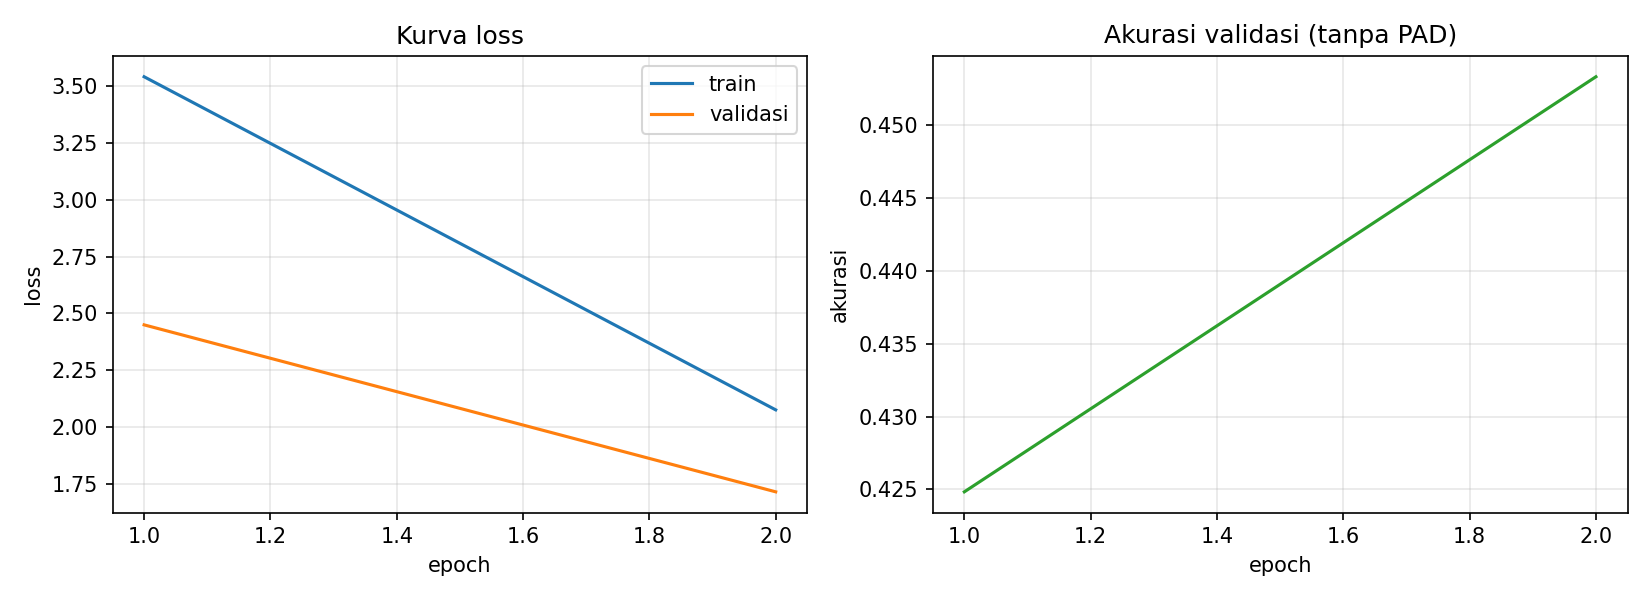

total 68096
drwxr-xr-x 2 root root     4096 Nov  2 07:25 .
drwxr-xr-x 4 root root     4096 Nov  2 07:25 ..
-rw-r--r-- 1 root root 17428554 Nov  2 07:25 best_integrasi.pt
-rw-r--r-- 1 root root 17428094 Nov  2 07:24 best_smoke.pt
-rw-r--r-- 1 root root 17428554 Nov  2 07:25 last_integrasi.pt
-rw-r--r-- 1 root root 17428094 Nov  2 07:24 last_smoke.pt


In [11]:
# 5c. Lihat metrik & grafik
import pandas as pd
from IPython.display import Image, display
print(pd.read_csv("outputs/metrics_integrasi.csv").to_string(index=False))
display(Image("outputs/loss_curve_integrasi.png"))
!ls -la outputs/checkpoints

## Tahap 6 — `generate.py` (Anggota 3)

In [12]:
!python src/generate.py --checkpoint outputs/checkpoints/best_integrasi.pt --n-samples 2 --max-new-tokens 512 --seed 42
!ls -la outputs/generated

Checkpoint epoch 2 (nilai 1.7159) | cuda
[1/2] 512 token baru -> /content/midi-generator/outputs/generated/sample_20261102_072550_01_T0.95_k40.mid
[2/2] 512 token baru -> /content/midi-generator/outputs/generated/sample_20261102_072550_02_T0.95_k40.mid
total 16
drwxr-xr-x 2 root root 4096 Nov  2 07:25 .
drwxr-xr-x 5 root root 4096 Nov  2 07:25 ..
-rw-r--r-- 1 root root 1546 Nov  2 07:25 sample_20261102_072550_01_T0.95_k40.mid
-rw-r--r-- 1 root root 1735 Nov  2 07:25 sample_20261102_072550_02_T0.95_k40.mid


In [13]:
# 6b. Dengarkan hasil (sintesis gelombang sederhana, tanpa soundfont)
from IPython.display import Audio
hasil = sorted(Path("outputs/generated").glob("*.mid"))
assert hasil, "Tidak ada file .mid hasil generate!"
for f in hasil[:2]:
    pm = pretty_midi.PrettyMIDI(str(f))
    notes = pm.instruments[0].notes if pm.instruments else []
    print(f"{f.name}: {len(notes)} nada, {pm.get_end_time():.1f} detik")
    display(Audio(pm.synthesize(fs=16000), rate=16000))
print("\n✅ LULUS — alur end-to-end berjalan dari MIDI sampai MIDI baru")

sample_20261102_072550_01_T0.95_k40.mid: 246 nada, 65.6 detik


sample_20261102_072550_02_T0.95_k40.mid: 244 nada, 124.6 detik



✅ LULUS — alur end-to-end berjalan dari MIDI sampai MIDI baru


## 📋 Hasil Uji Integrasi #1 (isi setelah semua sel dijalankan)

| Tahap | Modul | Lulus? | Angka / catatan penting |
|---|---|---|---|
| 0 | Persiapan | | Commit diuji: ... ; GPU: ... |
| 1 | tokenizer.py | | Round-trip identik: .../20 |
| 2 | Asumsi 2 & 3 | | DUR_16: ...% ; median token/lagu: ... ; lagu > 256: ...% |
| 3 | model.py | | Parameter: ... ; loss awal: ... |
| 4 | dataset.py + model | | Chunk train/val: ... / ... |
| 5 | train.py | | Epoch 2: train_loss ... ; val_loss ... ; val_acc ... |
| 6 | generate.py | | Jumlah nada sampel 1: ... ; durasi: ... detik |

**Keputusan Ketua:** (contoh: asumsi 2 aman → `MAX_DURATION` tetap 16; alur siap untuk training penuh oleh Anggota 3)